# Oráculo Grover

---
# Parte 0 · Preparación

Si esta celda falla con `ModuleNotFoundError`, el notebook está usando un Python que no tiene las dependencias.
En VS Code: **Select Kernel → Python Environments →** `.venv` (uv) o `grover-practica` (conda). En Jupyter Lab,
ábrelo con `uv run jupyter lab` o desde el entorno conda activado.

In [1]:
%matplotlib inline
import math
import random
import sys

import numpy as np
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
from qiskit import ClassicalRegister, QuantumCircuit, transpile
from qiskit.circuit.library import MCMTGate, MCXGate, ZGate, grover_operator
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

print("Python    ", sys.version.split()[0], "  ", sys.executable)
print("qiskit    ", qiskit.__version__)
print("qiskit-aer", qiskit_aer.__version__)

Python     3.12.13    /Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/bin/python
qiskit     2.6.1
qiskit-aer 0.18.2


### Herramientas

La siguiente celda define funciones de apoyo: simular, graficar y autocorregir. **No hace falta leerla ahora**;
las piezas importantes de Grover (MCZ, oracles, difusor) las construyes tú a lo largo de la práctica.

Convención de bits (la de Qiskit): el string `"q_{n-1} … q_1 q_0"`. **El qubit 0 es el carácter de la derecha.**

In [2]:
# ------------------------------------------------------------------ simulación
SIM = AerSimulator()


def statevector(qc):
    """Vector de estado exacto (se ignoran las mediciones finales)."""
    return Statevector(qc.remove_final_measurements(inplace=False))


def amplitudes(qc, n=None):
    """Amplitudes de los 2^n estados de búsqueda (las ancillas, si hay, deben terminar en |0>)."""
    n = qc.num_qubits if n is None else n
    return statevector(qc).data[: 2**n]


def probabilities(qc, n=None):
    """Probabilidad exacta de cada string de n bits."""
    n = qc.num_qubits if n is None else n
    probs = statevector(qc).probabilities(qargs=list(range(n)))
    return {format(i, f"0{n}b"): float(p) for i, p in enumerate(probs)}


def simulated_success(qc, marked, n=None):
    """Probabilidad exacta de medir alguno de los estados marcados."""
    probs = probabilities(qc, n)
    return sum(probs[s] for s in set(marked))


def counts(qc, shots=1024, n=None, seed=None):
    """Ejecuta en AerSimulator. Si el circuito no mide, se miden los primeros n qubits."""
    if qc.num_clbits == 0:
        n = qc.num_qubits if n is None else n
        qc = qc.copy()
        creg = ClassicalRegister(n, "meas")
        qc.add_register(creg)
        qc.measure(range(n), creg)
    result = SIM.run(transpile(qc, SIM), shots=shots, seed_simulator=seed).result()
    return dict(result.get_counts())


# ------------------------------------------------------------------ fórmulas (Partes 3 y 4)
def theta(N, M):
    """sin θ = sqrt(M/N)."""
    return math.asin(math.sqrt(M / N))


def optimal_t(N, M):
    """Entero más cercano a π/(4θ) - 1/2, que es floor(π/(4θ)). Con M = 0, t = 0."""
    th = theta(N, M)
    return 0 if th == 0 else math.floor(math.pi / (4 * th))


def success_probability(N, M, t):
    """P(medir un marcado tras t iteraciones) = sin²((2t+1)θ)."""
    return math.sin((2 * t + 1) * theta(N, M)) ** 2


# ------------------------------------------------------------------ autocorrección
def oracle_block(qc, n=None):
    """Matriz sobre los n qubits de búsqueda con las ancillas en |0> (comprueba que vuelvan a |0>)."""
    n = qc.num_qubits if n is None else n
    block = Operator(qc).data[: 2**n, : 2**n]
    if not np.allclose(block.conj().T @ block, np.eye(2**n), atol=1e-8):
        raise AssertionError("Las ancillas no vuelven a |0>: falta deshacer (uncompute) los cálculos auxiliares.")
    return block


def show_phases(qc, n=None):
    """Imprime la fase (+1 / -1) de cada estado de la base y devuelve los que tienen -1."""
    n = qc.num_qubits if n is None else n
    block = oracle_block(qc, n)
    if not np.allclose(block - np.diag(np.diag(block)), 0, atol=1e-8):
        print("Ojo: la matriz no es diagonal, así que no es un oracle de fase.")
    negative = []
    for i, d in enumerate(np.diag(block)):
        s = format(i, f"0{n}b")
        sign = "-1" if np.isclose(d, -1) else "+1" if np.isclose(d, 1) else f"{complex(d):.3f}"
        if sign == "-1":
            negative.append(s)
        if n <= 4 or sign != "+1":
            print(f"|{s}⟩ : {sign}")
    if n > 4:
        print(f"(los otros {2**n - len(negative)} estados tienen fase +1)")
    return negative


def check_oracle(qc, marked, n=None):
    """Comprueba que qc sea el oracle de fase del conjunto `marked`."""
    marked = list(marked)
    n = qc.num_qubits if n is None else n
    try:
        block = oracle_block(qc, n)
    except AssertionError as err:
        print(f"[X] {err}")
        return False
    if not np.allclose(block - np.diag(np.diag(block)), 0, atol=1e-8):
        print("[X] No es diagonal: tu circuito mueve amplitud entre estados.")
        print("   Un oracle de fase solo cambia signos, nunca cambia |x> por otro |y>.")
        return False
    got = np.real_if_close(np.diag(block))
    want = np.ones(2**n)
    for s in set(marked):
        want[int(s, 2)] = -1
    wrong = [format(i, f"0{n}b") for i in range(2**n) if not np.isclose(got[i], want[i])]
    if not wrong:
        print(f"[OK] Correcto: el oracle marca exactamente {sorted(set(marked)) or 'ningún estado'}.")
        return True
    if np.allclose(got, -want):
        print("[!]  Coincide salvo una fase global -1 (marca justo lo contrario). Revisa la construcción.")
        return False
    print(f"[X] Fase incorrecta en: {wrong}")
    missing = [s for s in wrong if s in marked]
    extra = [s for s in wrong if s not in marked]
    if missing:
        print(f"   Deberían tener fase -1: {missing}")
    if extra:
        print(f"   No deberían estar marcados: {extra}")
    return False


def check_t(n, M, t):
    """Comprueba una predicción del número óptimo de iteraciones."""
    best = optimal_t(2**n, M)
    if t == best:
        print(f"[OK] Correcto: con N = {2**n} y M = {M}, t_opt = {best}.")
        return True
    print(f"[X] Para N = {2**n} y M = {M} el óptimo no es {t}. Pista: t ≈ π/(4θ) - 1/2.")
    return False


# ------------------------------------------------------------------ gráficas
def show(qc, **kwargs):
    """Dibuja un circuito (cerrando la figura para que no salga dos veces)."""
    fig = qc.draw("mpl", **kwargs)
    display(fig)
    plt.close(fig)


def histograma(data, **kwargs):
    """plot_histogram de Qiskit, mostrado una sola vez."""
    fig = plot_histogram(data, **kwargs)
    display(fig)
    plt.close(fig)


SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NORMAL, MARKED, TEXT, GRID = SERIES[0], SERIES[1], "#52514e", "#e5e4df"


def _style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=TEXT, labelsize=9)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def plot_amplitudes(state, marked=(), n=None, title=None, show_mean=True, ax=None):
    """Barras con las amplitudes (con signo). Naranja = marcado; línea punteada = media."""
    if isinstance(state, Statevector):
        n = state.num_qubits if n is None else n
        amps = state.data[: 2**n]
    else:
        n = state.num_qubits if n is None else n
        amps = amplitudes(state, n)
    if not np.allclose(np.imag(amps), 0, atol=1e-9):
        raise ValueError("Las amplitudes tienen parte imaginaria; esta gráfica solo muestra amplitudes reales.")
    real = np.real(amps)
    labels = [format(i, f"0{n}b") for i in range(2**n)]
    marked = set(marked)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(6, 0.32 * 2**n), 3.2))
    ax.bar(range(2**n), real, color=[MARKED if s in marked else NORMAL for s in labels], width=0.7)
    ax.axhline(0, color=TEXT, linewidth=0.8)
    handles = [plt.Rectangle((0, 0), 1, 1, color=NORMAL, label="no marcado")]
    if marked:
        handles.append(plt.Rectangle((0, 0), 1, 1, color=MARKED, label="marcado"))
    if show_mean:
        ax.axhline(real.mean(), color=TEXT, linestyle="--", linewidth=1)
        handles.append(plt.Line2D([], [], color=TEXT, linestyle="--", label="media"))
    ax.set_xticks(range(2**n))
    ax.set_xticklabels(labels, rotation=90 if n > 3 else 0, fontsize=8 if n > 4 else 9)
    ax.set_ylabel("amplitud")
    lim = max(1e-9, np.abs(real).max()) * 1.15
    ax.set_ylim(-lim, lim)
    if title:
        ax.set_title(title, fontsize=11)
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    _style(ax)
    return ax


def plot_success_vs_t(N, Ms, t_max=None, simulated=None, highlight_t=None, ax=None):
    """P(éxito) = sin²((2t+1)θ) contra t. `simulated` = {M: [P(0), P(1), ...]}."""
    Ms = [Ms] if isinstance(Ms, int) else list(Ms)
    if t_max is None:
        t_max = max(3, 3 * max(optimal_t(N, M) for M in Ms) + 2)
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3.4))
    tt = np.linspace(0, t_max, 400)
    ts = np.arange(t_max + 1)
    for i, M in enumerate(Ms):
        c = SERIES[i % len(SERIES)]
        ax.plot(tt, np.sin((2 * tt + 1) * theta(N, M)) ** 2, color=c, linewidth=1, alpha=0.35)
        ax.plot(ts, [success_probability(N, M, t) for t in ts], "o", color=c, markersize=6, label=f"M = {M} (teoría)")
        if simulated and M in simulated:
            ax.plot(range(len(simulated[M])), simulated[M], "x", color=TEXT, markersize=7, label=f"M = {M} (simulación)")
        if M:
            ax.axvline(optimal_t(N, M), color=c, linestyle=":", linewidth=1)
    if highlight_t is not None:
        ax.axvspan(highlight_t - 0.3, highlight_t + 0.3, color=GRID, alpha=0.8, zorder=0, label=f"t = {highlight_t}")
    ax.set_xlabel("t (iteraciones de Grover)")
    ax.set_ylabel("P(medir un marcado)")
    ax.set_ylim(-0.03, 1.05)
    ax.set_xticks(ts if t_max <= 20 else np.linspace(0, t_max, 11).astype(int))
    ax.set_title(f"N = {N}: las líneas punteadas marcan t_opt", fontsize=11)
    ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    _style(ax)
    return ax


def plot_geometry(N, M, t, ax=None):
    """Cada iteración rota el estado 2θ hacia |w>. Horizontal: |w⊥>; vertical: |w>."""
    th = theta(N, M)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.2, 4.2))
    circle = np.linspace(-math.pi, math.pi, 400)
    ax.plot(np.cos(circle), np.sin(circle), color=GRID, linewidth=1)
    ax.axhline(0, color=GRID, linewidth=1)
    ax.axvline(0, color=GRID, linewidth=1)
    for k in range(t + 1):
        ang, last = (2 * k + 1) * th, k == t
        ax.annotate("", xy=(math.cos(ang), math.sin(ang)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=MARKED if last else NORMAL,
                                    lw=2 if last else 1, alpha=1 if last else 0.45))
        ax.text(1.08 * math.cos(ang), 1.08 * math.sin(ang), f"t={k}", fontsize=8, color=TEXT, ha="center", va="center")
    ax.text(1.12, -0.08, "|w⊥⟩", color=TEXT, fontsize=10)
    ax.text(0.04, 1.1, "|w⟩", color=TEXT, fontsize=10)
    ax.set_xlim(-1.25, 1.35)
    ax.set_ylim(-1.25, 1.3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(f"θ = {math.degrees(th):.1f}°, t = {t}: P = {success_probability(N, M, t):.3f}", fontsize=10)
    return ax


print("Herramientas listas.")

Herramientas listas.


Prueba rápida: un estado de Bell en Aer. Deben salir `00` y `11` mitad y mitad.

In [3]:
from qiskit import QuantumCircuit, QuantumRegister

x = QuantumRegister(3, 'x')
c = QuantumRegister(3, 'c')

comp = QuantumCircuit(x, c)
comp.x([x[0], x[1]]); comp.ccx(x[0], x[1], c[0]); comp.x(c[0]); comp.x([x[0], x[1]])
comp.x(x[2]);         comp.ccx(x[0], x[2], c[1]); comp.x(c[1]); comp.x(x[2])
comp.ccx(x[1], x[2], c[2]); comp.x(c[2])

oracle = QuantumCircuit(x, c)
oracle.compose(comp, inplace=True)          # calcular
oracle.h(c[2]); oracle.ccx(c[0], c[1], c[2]); oracle.h(c[2])   # CCZ


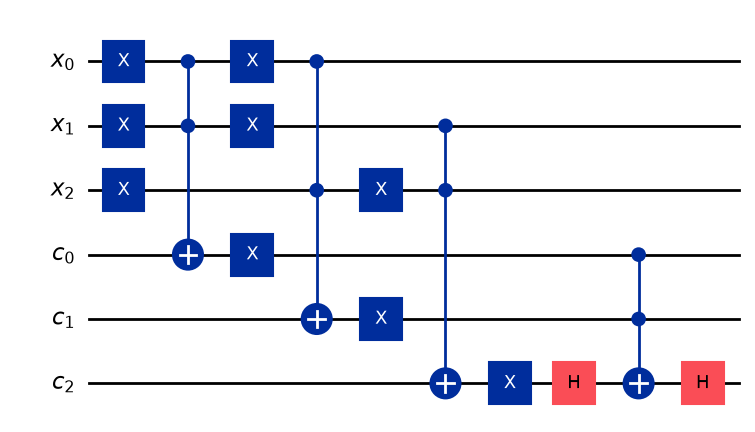

In [4]:
show(oracle)
oracle.compose(comp.inverse(), inplace=True)  # descalcular

---
# Grover completo con el oracle de arriba

El oracle usa 3 qubits de búsqueda (`x`) y 3 ancillas (`c`), así que $N = 2^3 = 8$.
Como no sabemos cuántas soluciones $M$ hay, probamos todas las iteraciones
$t \in \{1, \dots, \lfloor \tfrac{\pi}{4}\sqrt{N} \rfloor\}$.

Primero, qué estados marca el oracle:

In [5]:
n = 3
N = 2**n
T_MAX = math.floor(math.pi / 4 * math.sqrt(N))
print(f"N = {N}, t ∈ {{1, …, {T_MAX}}}")
marked = show_phases(oracle, n)
print("Marcados:", marked, "-> M =", len(marked))

N = 8, t ∈ {1, …, 2}
|000⟩ : +1
|001⟩ : +1
|010⟩ : -1
|011⟩ : +1
|100⟩ : +1
|101⟩ : -1
|110⟩ : +1
|111⟩ : +1
Marcados: ['010', '101'] -> M = 2


### Circuito de Grover

$H^{\otimes n}$ sobre `x`, luego $t$ veces (oracle + difusor), y medición de `x`.
El difusor es $H^{\otimes n} X^{\otimes n}\,\text{CCZ}\,X^{\otimes n} H^{\otimes n}$ sobre `x`.

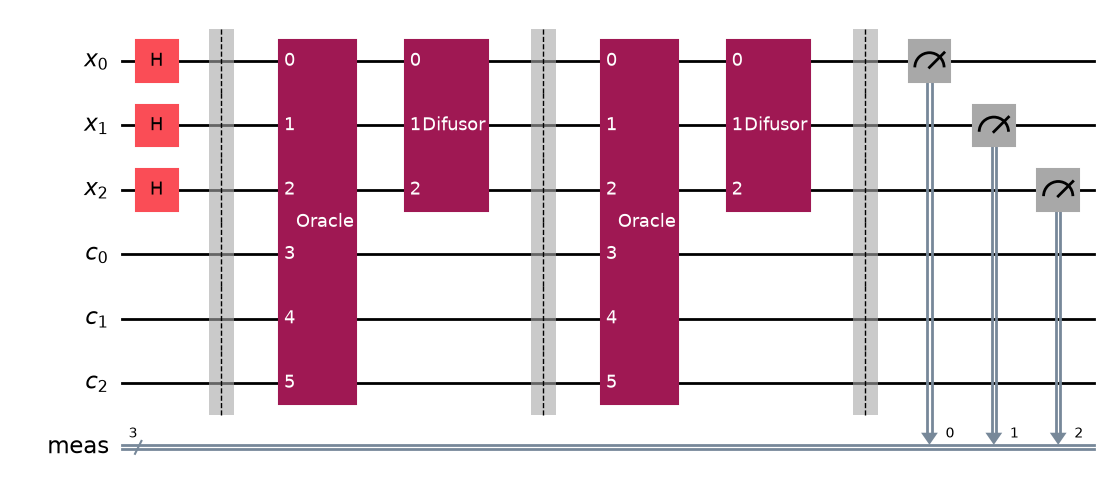

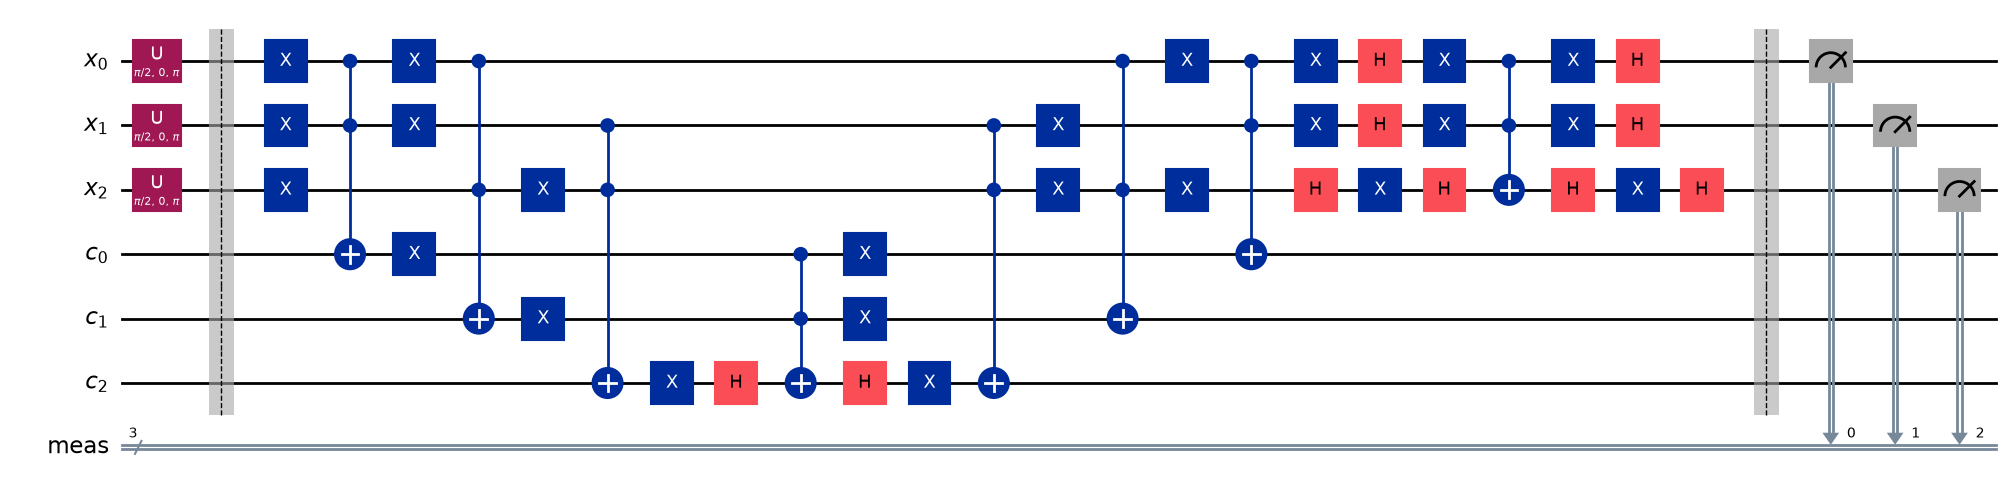

In [6]:
def diffuser(n):
    qc = QuantumCircuit(n, name="Difusor")
    qc.h(range(n)); qc.x(range(n))
    qc.h(n - 1); qc.mcx(list(range(n - 1)), n - 1); qc.h(n - 1)   # MCZ
    qc.x(range(n)); qc.h(range(n))
    return qc


def grover_circuit(oracle, n, t, measure=True):
    xr, cr = QuantumRegister(n, "x"), QuantumRegister(oracle.num_qubits - n, "c")
    qc = QuantumCircuit(xr, cr)
    qc.h(xr)
    qc.barrier()
    orc = oracle.to_gate(label="Oracle")
    dif = diffuser(n).to_gate(label="Difusor")
    for _ in range(t):
        qc.append(orc, qc.qubits)
        qc.append(dif, list(xr))
        qc.barrier()
    if measure:
        m = ClassicalRegister(n, "meas")
        qc.add_register(m)
        qc.measure(xr, m)
    return qc


# circuito completo con t = T_MAX (compuertas agrupadas)
show(grover_circuit(oracle, n, T_MAX))
# mismo circuito con el oracle desplegado
show(grover_circuit(oracle, n, 1).decompose(), fold=40)

### Emulador sin ruido y con ruido

Ruido: despolarizante de 0.1 % en compuertas de 1 qubit y 1 % en `cx`, más 2 % de error de lectura.
El circuito se transpila a la base `{cx, id, rz, sx, x}`, así que cada Toffoli se vuelve varios `cx` ruidosos.

In [7]:
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error

BASIS = ["cx", "id", "rz", "sx", "x"]
noise = NoiseModel(basis_gates=BASIS)
noise.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["id", "rz", "sx", "x"])
noise.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])
noise.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))

ideal_sim = AerSimulator()
noisy_sim = AerSimulator(noise_model=noise)
SHOTS = 4096


def run(qc, sim):
    tqc = transpile(qc, sim, basis_gates=BASIS, optimization_level=1, seed_transpiler=7)
    return sim.run(tqc, shots=SHOTS, seed_simulator=7).result().get_counts(), tqc


results = {}
for t in range(1, T_MAX + 1):
    qc = grover_circuit(oracle, n, t)
    ci, _ = run(qc, ideal_sim)
    cn, tq = run(qc, noisy_sim)
    results[t] = (ci, cn)
    pi_ = sum(ci.get(s, 0) for s in marked) / SHOTS
    pn_ = sum(cn.get(s, 0) for s in marked) / SHOTS
    print(f"t = {t}: P(éxito) sin ruido = {pi_:.3f}, con ruido = {pn_:.3f}   (cx tras transpilar: {tq.count_ops().get('cx', 0)})")

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 1: P(éxito) sin ruido = 1.000, con ruido = 0.667   (cx tras transpilar: 48)
t = 2: P(éxito) sin ruido = 0.254, con ruido = 0.269   (cx tras transpilar: 96)


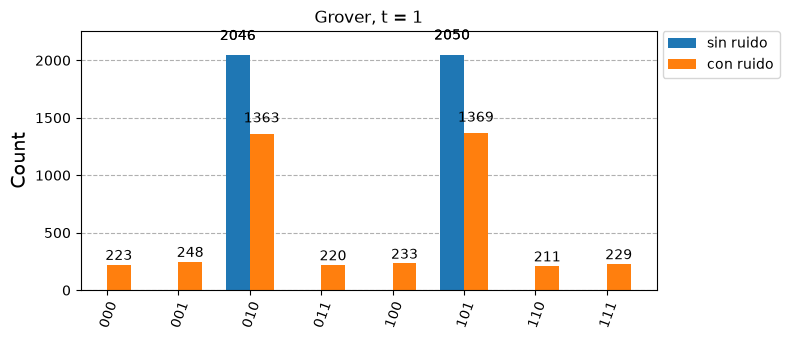

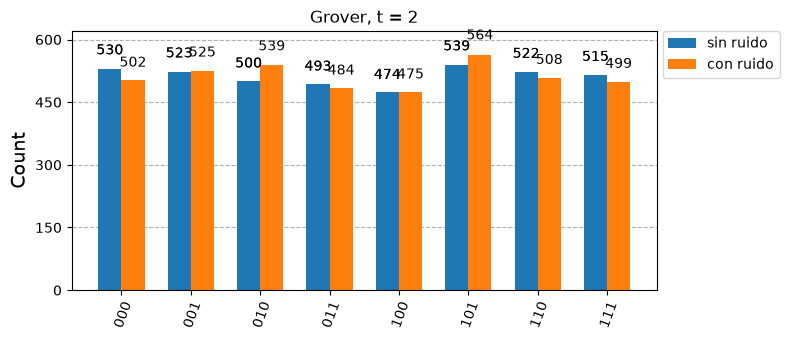

In [8]:
for t, (ci, cn) in results.items():
    histograma([ci, cn], legend=["sin ruido", "con ruido"], title=f"Grover, t = {t}", figsize=(8, 3.5))

---
# Tres ejemplos más grandes

Ahora el mismo procedimiento sobre problemas reales: **SAT**, **factorización** y **subset-sum**.
En los tres el oracle calcula una condición en ancillas, aplica una fase $-1$ si se cumple y deshace el cálculo
(*compute → fase → uncompute*). Los $n$ qubits de búsqueda son siempre los primeros del oracle, así que
`grover_circuit` funciona sin cambios. Como $M$ es desconocido, se prueba cada $t \in \{1,\dots,\lfloor\frac{\pi}{4}\sqrt N\rfloor\}$.

Estos circuitos tienen cientos de `cx`, así que con el 1 % de error de antes todo se vuelve ruido uniforme.
Para ver algo más que ruido, aquí el error de `cx` es de 0.1 % (y 0.01 % en 1 qubit, 0.5 % de lectura).

In [9]:
from qiskit.circuit.library import QFTGate, RGQFTMultiplier


def mcz(qc, qubits):
    """Z multicontrolada sobre `qubits` (H · MCX · H sobre el último)."""
    qubits = list(qubits)
    qc.h(qubits[-1]); qc.mcx(qubits[:-1], qubits[-1]); qc.h(qubits[-1])


def bits(v, n):
    """Bits de v, el bit 0 primero (el qubit i de Qiskit es el bit i)."""
    return [(v >> i) & 1 for i in range(n)]


def phase_oracle(compute, n, target_qubits):
    """compute → MCZ sobre `target_qubits` → compute⁻¹."""
    o = QuantumCircuit(compute.num_qubits)
    o.compose(compute, inplace=True)
    mcz(o, target_qubits)
    o.compose(compute.inverse(), inplace=True)
    return o


def noise_model(scale=0.1):
    nm = NoiseModel(basis_gates=BASIS)
    nm.add_all_qubit_quantum_error(depolarizing_error(0.001 * scale, 1), ["id", "rz", "sx", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(0.01 * scale, 2), ["cx"])
    nm.add_all_qubit_readout_error(ReadoutError([[1 - 0.05 * scale, 0.05 * scale], [0.05 * scale, 1 - 0.05 * scale]]))
    return nm


def run_grover_example(oracle, n, marked, shots=1024, noise_scale=0.1, keep=8):
    """Grover completo con t = 1..⌊π√N/4⌋, sin y con ruido, para un oracle dado."""
    N, M = 2**n, len(set(marked))
    t_max = math.floor(math.pi / 4 * math.sqrt(N))
    print(f"n = {n}, N = {N}, M = {M}, qubits totales = {oracle.num_qubits}, t ∈ {{1,…,{t_max}}}")

    # el oracle de verdad marca lo que esperamos (y las ancillas vuelven a |0>)
    chk = QuantumCircuit(oracle.num_qubits); chk.h(range(n)); chk.compose(oracle, inplace=True)
    sv = Statevector(chk)
    neg = [format(i, f"0{n}b") for i in range(N) if sv.data[i].real < 0]
    assert sorted(neg) == sorted(set(marked)) and np.isclose(np.sum(np.abs(sv.data[N:]) ** 2), 0), "el oracle no coincide"
    print("[OK] el oracle marca exactamente", sorted(set(marked)))

    print("Oracle:")
    show(oracle, fold=40)
    print("Circuito de Grover completo:")
    show(grover_circuit(oracle, n, t_max), fold=40)

    nsim = AerSimulator(noise_model=noise_model(noise_scale))
    ideal, noisy, theory = [], [], []
    for t in range(1, t_max + 1):
        qc = grover_circuit(oracle, n, t)
        tqc = transpile(qc, ideal_sim, basis_gates=BASIS, optimization_level=1, seed_transpiler=7)
        ci = ideal_sim.run(tqc, shots=shots, seed_simulator=7).result().get_counts()
        cn = nsim.run(tqc, shots=shots, seed_simulator=7).result().get_counts()
        ideal.append(sum(ci.get(s, 0) for s in marked) / shots)
        noisy.append(sum(cn.get(s, 0) for s in marked) / shots)
        theory.append(success_probability(N, M, t))
        print(f"t = {t}: teoría {theory[-1]:.3f} | sin ruido {ideal[-1]:.3f} | con ruido {noisy[-1]:.3f}   (cx: {tqc.count_ops().get('cx', 0)})")
        histograma([ci, cn], legend=["sin ruido", "con ruido"], title=f"t = {t}", number_to_keep=keep, figsize=(8, 3.5))

    ts = range(1, t_max + 1)
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(ts, theory, "o-", color=SERIES[0], label="teoría")
    ax.plot(ts, ideal, "x", color=TEXT, markersize=8, label="sin ruido")
    ax.plot(ts, noisy, "s--", color=SERIES[1], label="con ruido")
    ax.set_xlabel("t"); ax.set_ylabel("P(éxito)"); ax.set_ylim(-0.03, 1.05); ax.set_xticks(list(ts))
    ax.legend(frameon=False, fontsize=8); _style(ax)
    plt.show()
    return ideal, noisy

## Ejemplo 1 · SAT con 5 variables y 9 cláusulas

Fórmula en CNF con 3 literales por cláusula (`k` = $x_k$, `-k` = $\lnot x_k$). El oracle usa una ancilla por cláusula:
la ancilla vale 1 si la cláusula se cumple (un OR es un `MCX` con las entradas negadas, seguido de `X`), y la fase $-1$
se aplica solo si **las 9 ancillas** valen 1. Total: 5 + 9 = 14 qubits, $N = 32$.

Soluciones (x5 x4 x3 x2 x1): ['00001', '00101']
n = 5, N = 32, M = 2, qubits totales = 14, t ∈ {1,…,4}
[OK] el oracle marca exactamente ['00001', '00101']
Oracle:


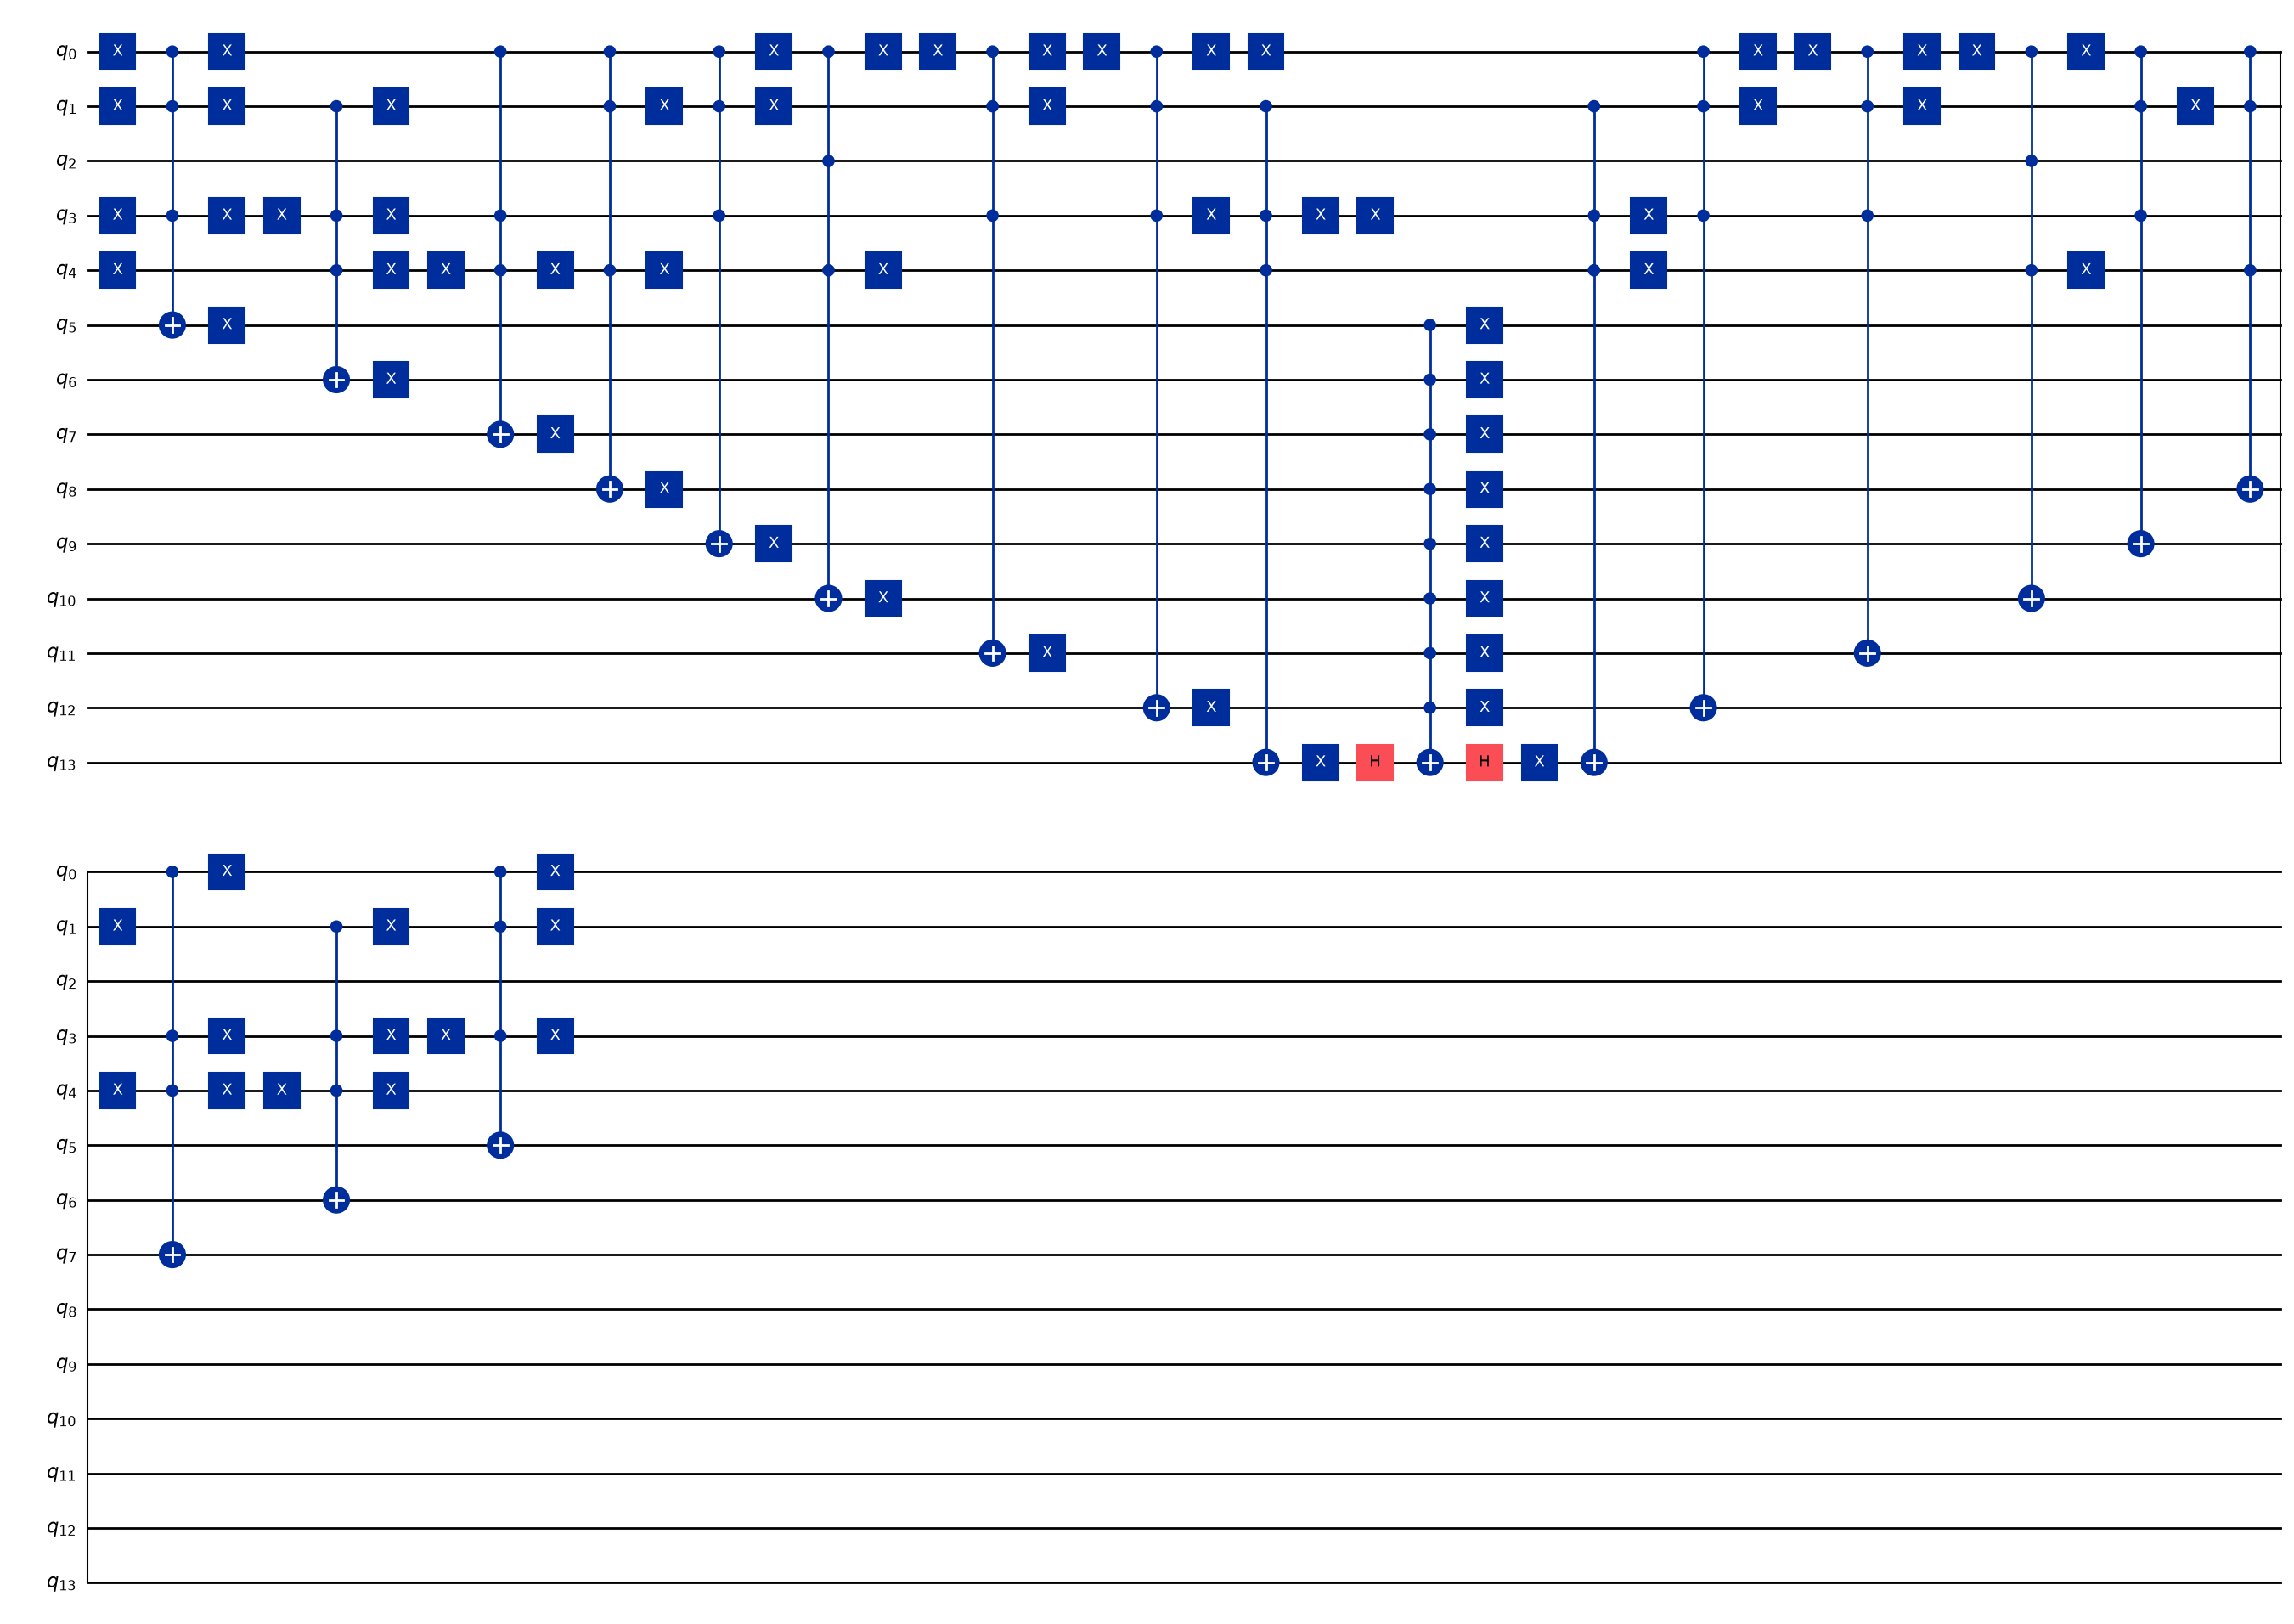

Circuito de Grover completo:


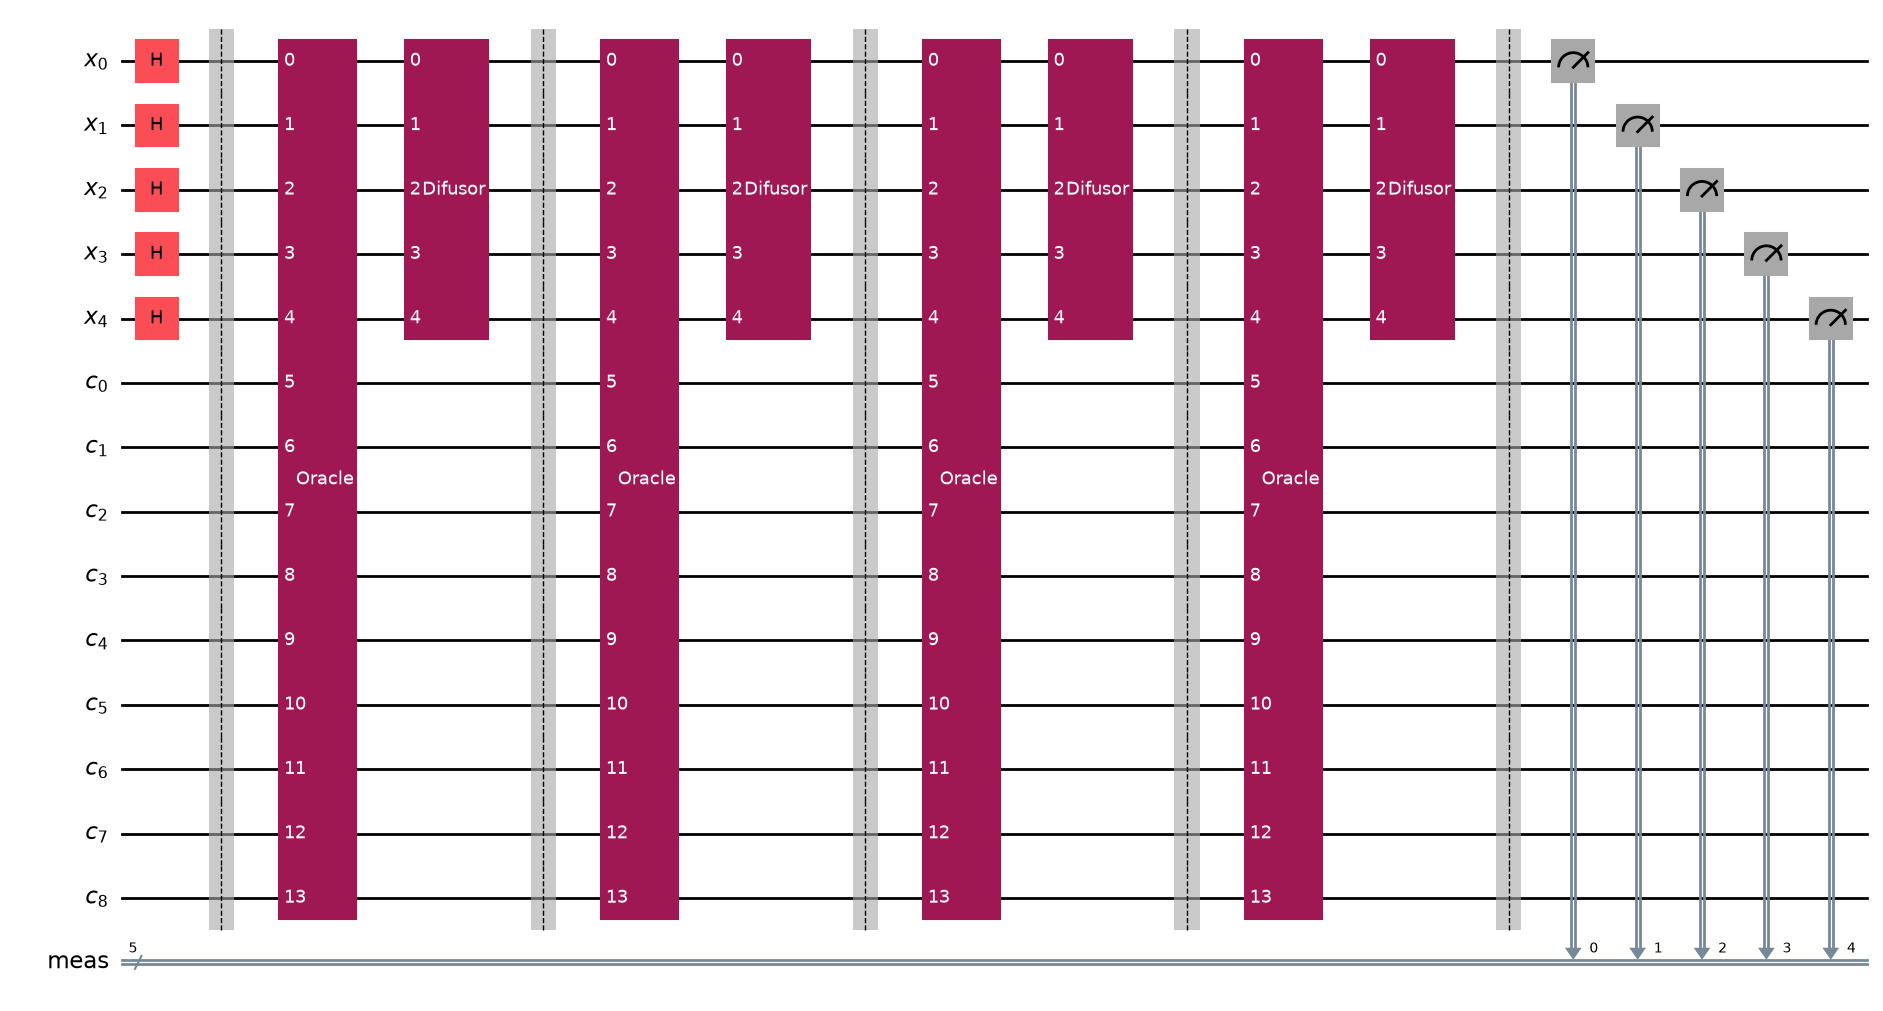

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 1: teoría 0.473 | sin ruido 0.487 | con ruido 0.318   (cx: 308)


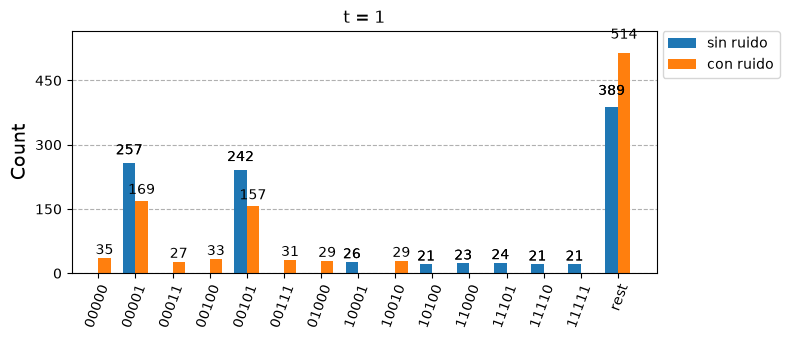

In [ ]:
n_sat = 5
clauses = [(1, 4, 2), (5, -2, 4), (5, -4, -1), (2, -5, -1), (-1, -4, -2),
           (-3, 1, 5), (2, 1, -4), (-4, -2, 1), (-5, 4, -2)]


def sat_oracle(clauses, n):
    k = len(clauses)
    comp = QuantumCircuit(n + k)
    for j, cl in enumerate(clauses):
        pos = [abs(l) - 1 for l in cl if l > 0]      # OR(l) = ¬AND(¬l): se niegan los literales positivos
        for q in pos: comp.x(q)
        comp.mcx([abs(l) - 1 for l in cl], n + j)
        comp.x(n + j)
        for q in pos: comp.x(q)
    return phase_oracle(comp, n, range(n, n + k))


sat = sat_oracle(clauses, n_sat)
sat_marked = [format(v, f"0{n_sat}b") for v in range(2**n_sat)
              if all(any((bits(v, n_sat)[abs(l) - 1] == 1) == (l > 0) for l in cl) for cl in clauses)]
print("Soluciones (x5 x4 x3 x2 x1):", sat_marked)
_ = run_grover_example(sat, n_sat, sat_marked)

## Ejemplo 2 · Factorizar $15$

Buscamos $a, b \in [0, 7]$ (3 bits cada uno, $n=6$, $N=64$) con $a\cdot b = 15$. El oracle multiplica en un registro
de 6 qubits (`RGQFTMultiplier`), compara el producto con la constante (X sobre los bits en 0 de 15 + `MCZ`) y deshace
la multiplicación. Las soluciones son $(3,5)$ y $(5,3)$; $1\cdot 15$ no cabe en 3 bits. El string de bits es `b a`.
Para otro número, cambia `N_f`.

Soluciones (b a): ['011101', '101011'] → [(5, 3), (3, 5)] (a, b)
n = 6, N = 64, M = 2, qubits totales = 12, t ∈ {1,…,6}
[OK] el oracle marca exactamente ['011101', '101011']


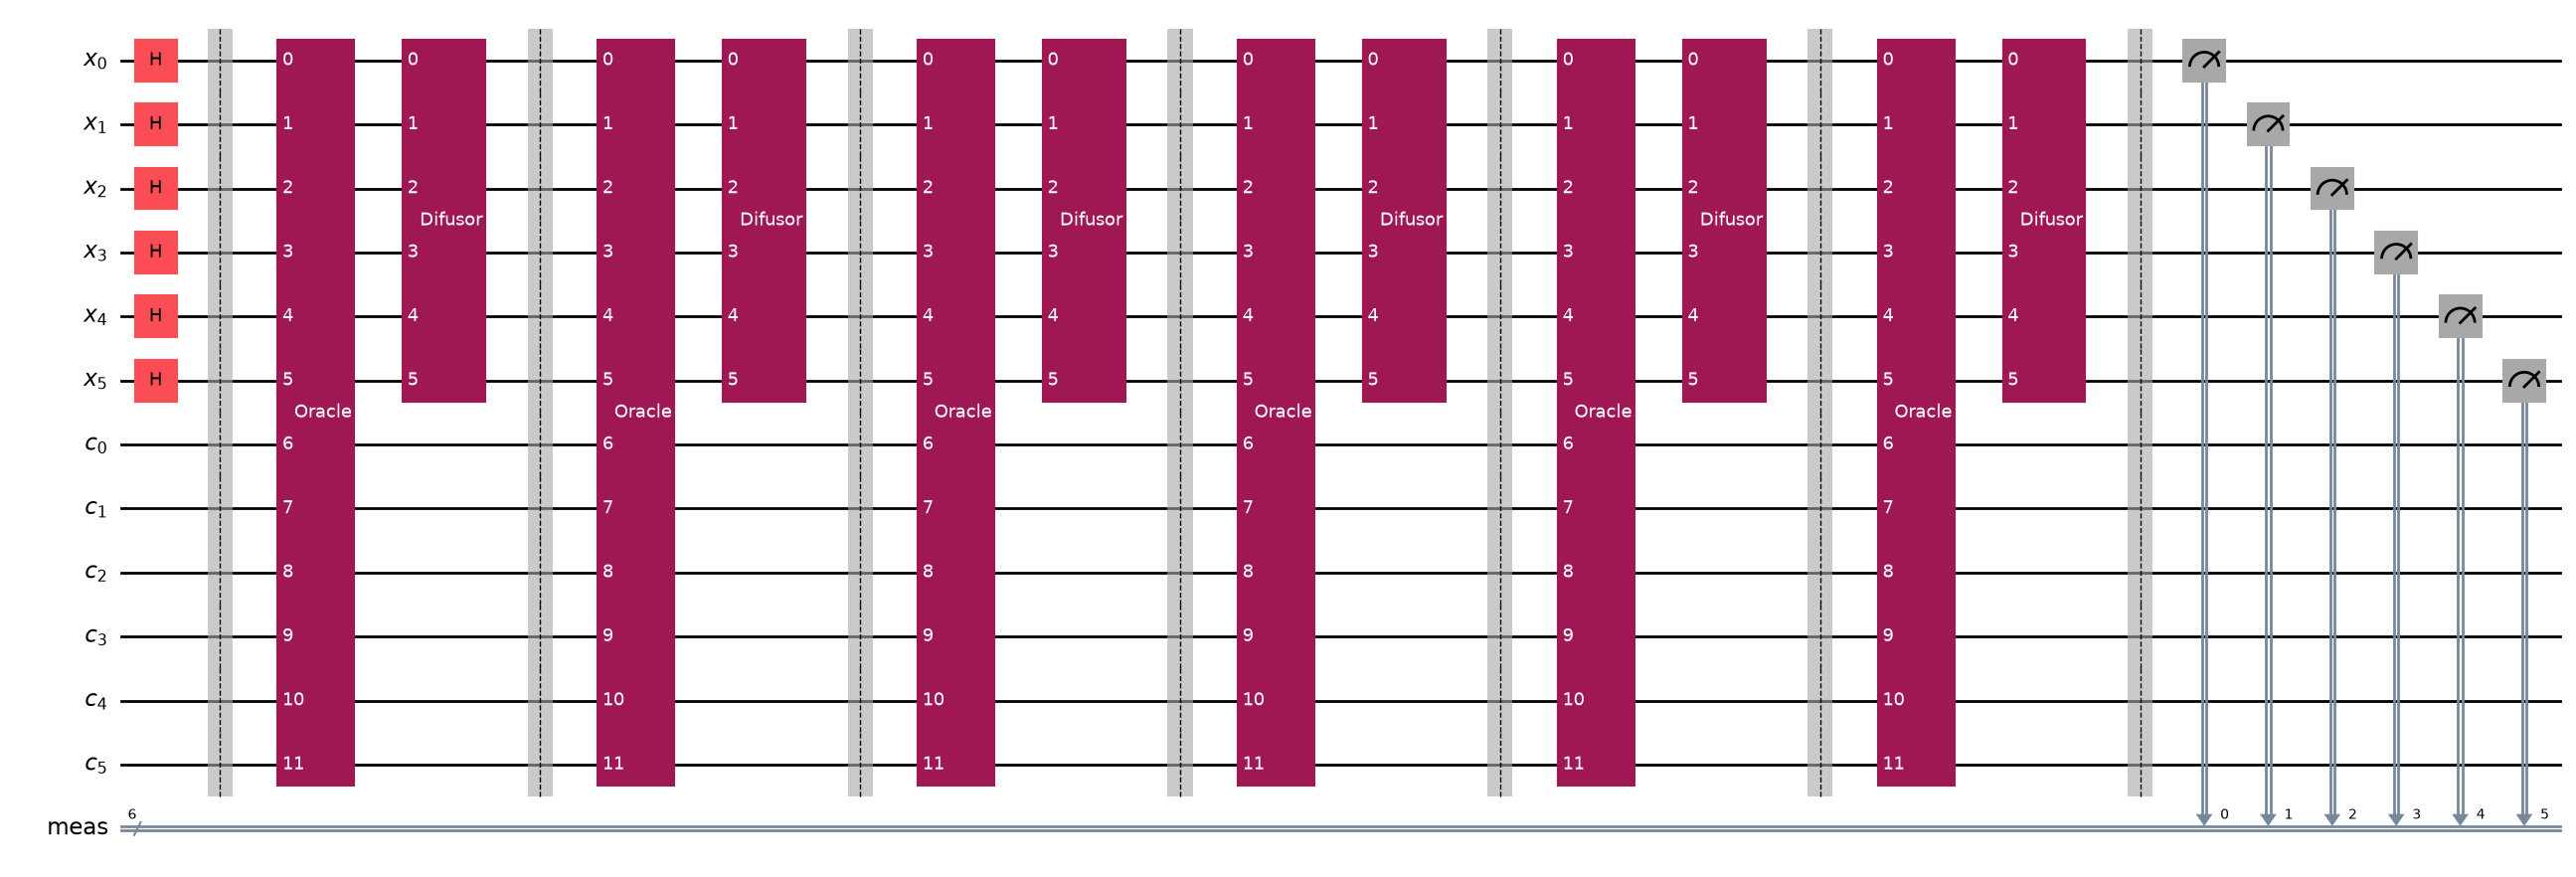

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 1: teoría 0.258 | sin ruido 0.270 | con ruido 0.136   (cx: 808)


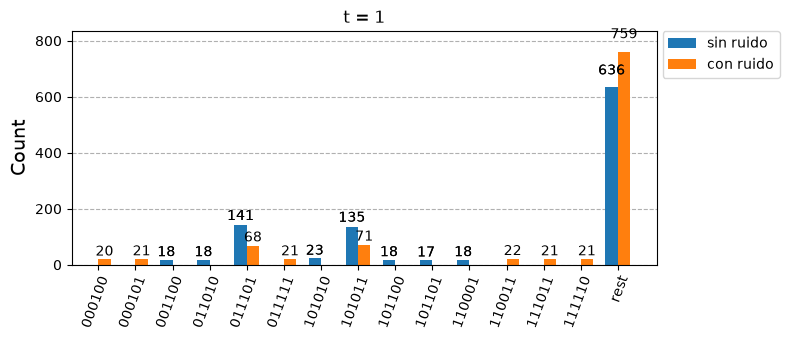

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 2: teoría 0.602 | sin ruido 0.621 | con ruido 0.168   (cx: 1616)


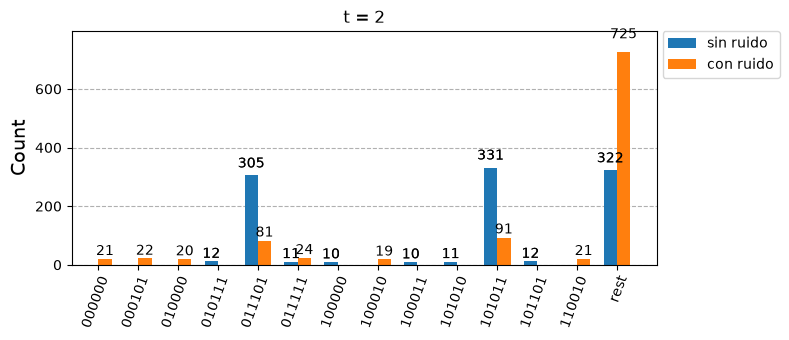

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 3: teoría 0.897 | sin ruido 0.909 | con ruido 0.141   (cx: 2424)


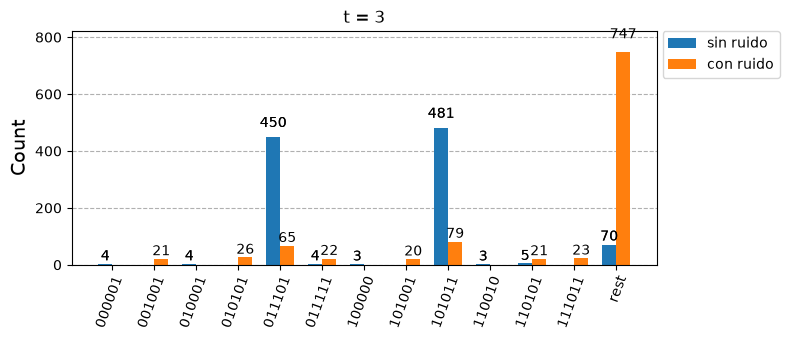

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 4: teoría 0.999 | sin ruido 0.999 | con ruido 0.094   (cx: 3232)


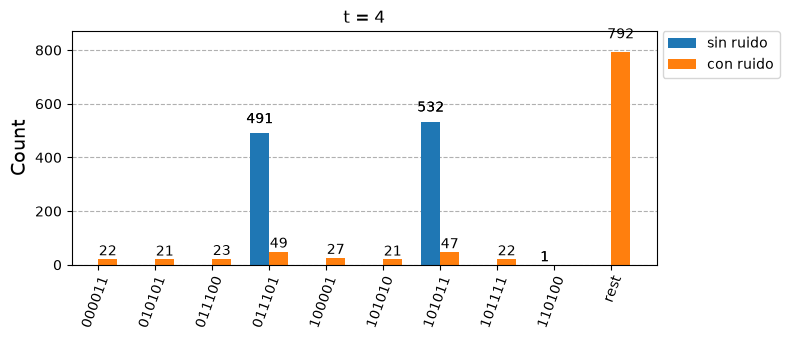

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 5: teoría 0.860 | sin ruido 0.866 | con ruido 0.073   (cx: 4040)


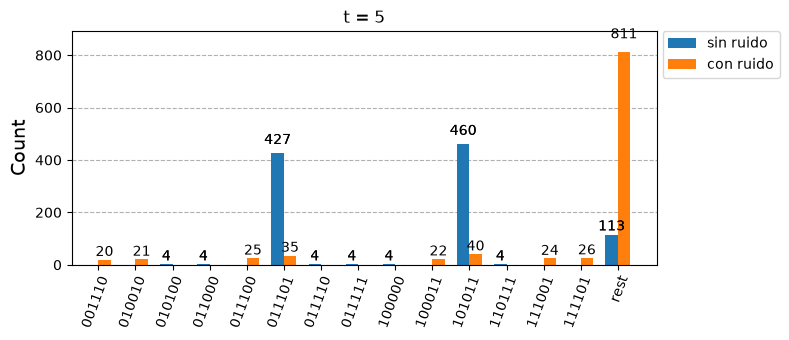

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 6: teoría 0.546 | sin ruido 0.578 | con ruido 0.058   (cx: 4848)


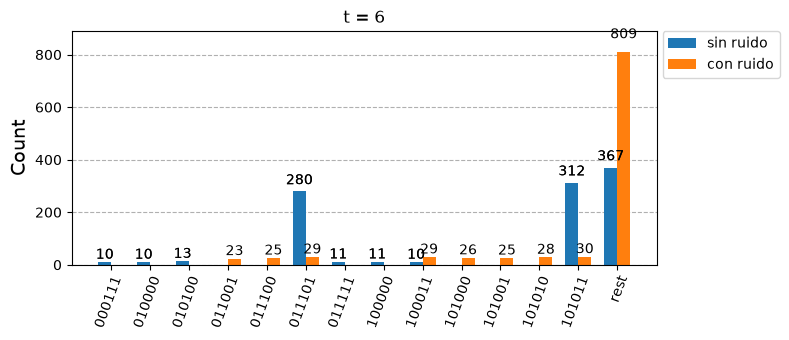

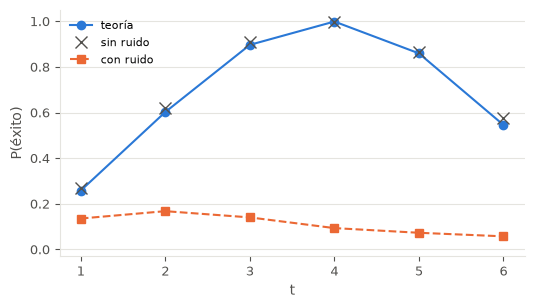

In [ ]:
N_f, k_bits = 15, 3


def factor_oracle(N_f, k):
    comp = QuantumCircuit(4 * k)                       # a (k), b (k), producto (2k)
    comp.compose(RGQFTMultiplier(k, 2 * k), inplace=True)
    zeros = [2 * k + i for i, bt in enumerate(bits(N_f, 2 * k)) if bt == 0]
    o = QuantumCircuit(4 * k)
    o.compose(comp, inplace=True)
    o.x(zeros); mcz(o, range(2 * k, 4 * k)); o.x(zeros)
    o.compose(comp.inverse(), inplace=True)
    return o


fac = factor_oracle(N_f, k_bits)
fac_marked = [format(v, f"0{2 * k_bits}b") for v in range(2 ** (2 * k_bits))
              if (v & 7) * (v >> 3) == N_f]
print("Soluciones (b a):", fac_marked, "→", [(int(s[3:], 2), int(s[:3], 2)) for s in fac_marked], "(a, b)")
_ = run_grover_example(fac, 2 * k_bits, fac_marked)

## Ejemplo 3 · Subset-sum

Dado $S = \{2, 3, 5, 7, 8\}$, ¿qué subconjuntos suman $10$? Cada qubit de búsqueda $x_i$ indica si $S_i$ entra al
subconjunto. El oracle suma en un registro de 5 qubits con un sumador de Draper (QFT, rotaciones de fase controladas
por $x_i$, QFT⁻¹), compara con el objetivo y deshace la suma. Total: 5 + 5 = 10 qubits, $N = 32$.

Soluciones (x5…x1): ['00111', '01010', '10001'] → [[2, 3, 5], [3, 7], [2, 8]]
n = 5, N = 32, M = 3, qubits totales = 10, t ∈ {1,…,4}
[OK] el oracle marca exactamente ['00111', '01010', '10001']


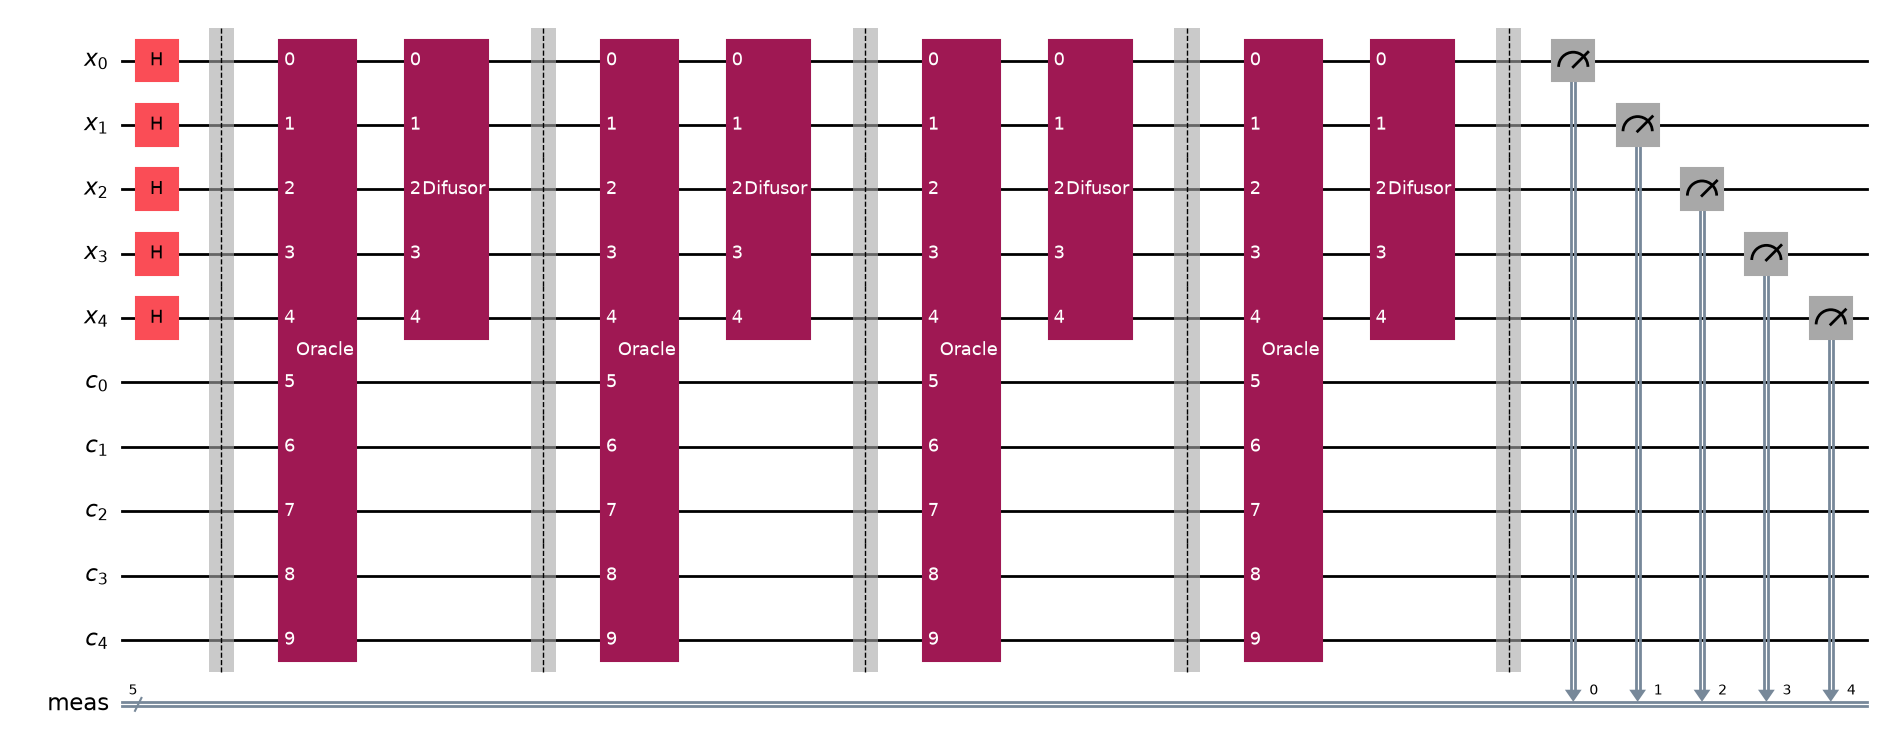

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 1: teoría 0.646 | sin ruido 0.668 | con ruido 0.547   (cx: 236)


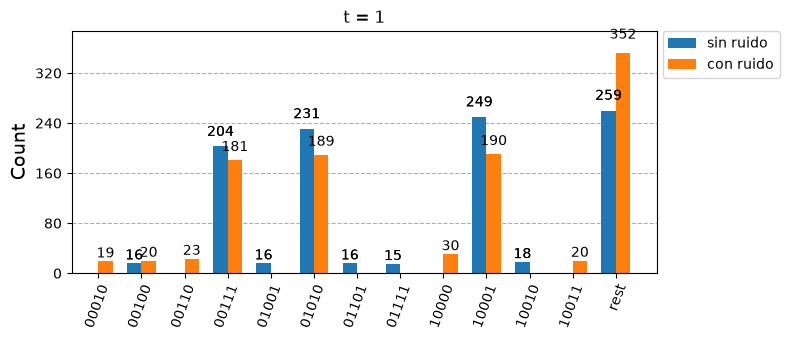

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 2: teoría 1.000 | sin ruido 0.999 | con ruido 0.671   (cx: 472)


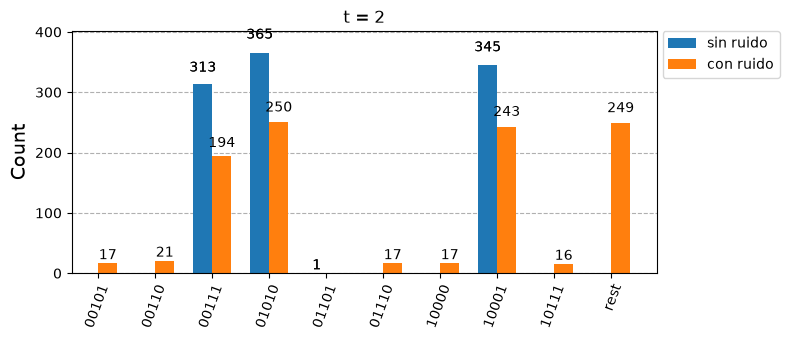

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 3: teoría 0.674 | sin ruido 0.692 | con ruido 0.491   (cx: 708)


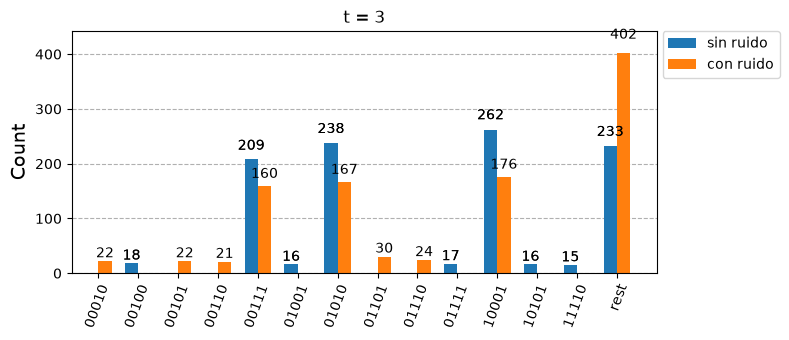

/Users/ju4ndiegos/Documents/Maestría/grover_practica/.venv/lib/python3.12/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


t = 4: teoría 0.112 | sin ruido 0.109 | con ruido 0.230   (cx: 944)


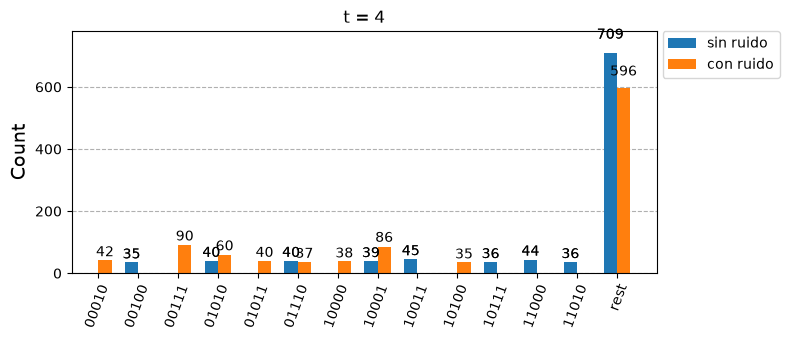

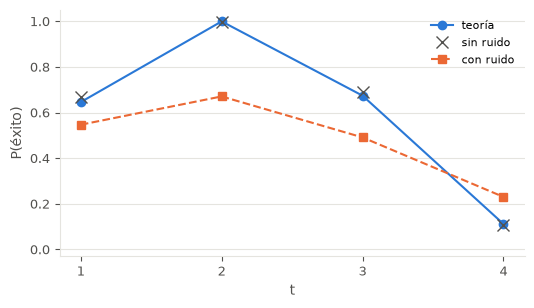

In [ ]:
S, target = [2, 3, 5, 7, 8], 10
m_bits = 5                                             # la suma máxima (25) cabe en 5 bits


def subset_oracle(S, target, w):
    m = len(S)
    comp = QuantumCircuit(m + w)
    reg = list(range(m, m + w))
    comp.append(QFTGate(w), reg)
    for i, v in enumerate(S):
        for j in range(w):
            comp.cp(2 * math.pi * v * 2**j / 2**w, i, m + j)
    comp.append(QFTGate(w).inverse(), reg)
    zeros = [m + i for i, bt in enumerate(bits(target, w)) if bt == 0]
    o = QuantumCircuit(m + w)
    o.compose(comp, inplace=True)
    o.x(zeros); mcz(o, reg); o.x(zeros)
    o.compose(comp.inverse(), inplace=True)
    return o


sub = subset_oracle(S, target, m_bits)
sub_marked = [format(v, f"0{len(S)}b") for v in range(2 ** len(S))
              if sum(S[i] for i in range(len(S)) if bits(v, len(S))[i]) == target]
print("Soluciones (x5…x1):", sub_marked, "→", [[S[i] for i in range(len(S)) if bits(int(s, 2), len(S))[i]] for s in sub_marked])
_ = run_grover_example(sub, len(S), sub_marked)